## **과제: 황순원의 '소나기'의 단어별 빈도 세기**
Key-Value RDD 프로그래밍을 활용하여 황순원의 '소나기'에 등장하는 단어별 빈도를 계산하는 과제입니다.
[+]에 해당되는 코드를 완성해주세요.

#### ✅ **핵심 학습 포인트**
+ RDD 기초 변환 함수 활용: ``map()``, ``flatMap()``, ``reduceByKey()``, ``sortBy()``

+ Key-Value 구조의 데이터 처리 방식 이해

+ 텍스트 마이닝의 기본 흐름 (입력 → 전처리 → 단어 추출 → 빈도 계산)

+ 분산 처리 환경에서의 Word Count 구현

### **1. Spark 애플리케이션 시작**

In [1]:
# [+] SparkConf, SparkContext 임포트
from pyspark import SparkConf, SparkContext

In [2]:
# [+] SparkConf, SparkContext 생성
conf = SparkConf().setMaster("local").setAppName("rainshower-word-count")
sc = SparkContext.getOrCreate(conf=conf)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/01 09:44:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### **2. 황순원의 소나기 원문(.txt) 불러오기**

In [3]:
# 파일 이름과 경로
path = '../data/'
filename = 'rainshower.txt'

In [4]:
# [+] 소나기 원문 파일(rainshower.txt)을 읽어 RDD 객체로 생성하기
lines = sc.textFile(path + filename)

**[+] RDD 값 100개(= 100 줄) 출력**

출력 결과:
```
['소년은 개울가에서 소녀를 보자 곧 윤 초시네 증손녀(曾孫女)딸이라는 걸 알 수 있었다. 소녀는 개울에다 손을 잠그고 물장난을 하고 있는 것이다. 서울서는 이런 개울물을 보지 못하기나 한 듯이.',
'벌써 며칠째 소녀는, 학교에서 돌아오는 길에 물장난이었다. 그런데, 어제까지 개울 기슭에서 하더니, 오늘은 징검다리 한가운데 앉아서 하고 있다.',
'소년은 개울둑에 앉아 버렸다. 소녀가 비키기를 기다리자는 것이다.',

...

'무명 겹저고리를 벗어 소녀의 어깨를 싸 주었다. 소녀는 비에 젖은 눈을 들어 한 번 쳐다보았을 뿐, 소년이 하는 대로 잠자코 있었다. 그리고는, 안고 온 꽃묶음 속에서 가지가 꺾이고 꽃이 일그러진 송이를 골라 발 밑에 버린다. 소녀가 들어선 곳도 비가 새기 시작했다. 더 거기서 비를 그을 수 없었다.',
'밖을 내다보던 소년이 무엇을 생각했는지 수수밭 쪽으로 달려간다. 세워 놓은 수숫단 속을 비집어 보더니, 옆의 수숫단을 날라다 덧세운다. 다시 속을 비집어 본다. 그리고는 이쪽을 향해 손짓을 한다.']
```



In [5]:
# [+] RDD 값 100개(= 100 줄) 출력
lines.take(100)

['소년은 개울가에서 소녀를 보자 곧 윤 초시네 증손녀(曾孫女)딸이라는 걸 알 수 있었다. 소녀는 개울에다 손을 잠그고 물장난을 하고 있는 것이다. 서울서는 이런 개울물을 보지 못하기나 한 듯이.',
 '벌써 며칠째 소녀는, 학교에서 돌아오는 길에 물장난이었다. 그런데, 어제까지 개울 기슭에서 하더니, 오늘은 징검다리 한가운데 앉아서 하고 있다.',
 '소년은 개울둑에 앉아 버렸다. 소녀가 비키기를 기다리자는 것이다.',
 '요행 지나가는 사람이 있어, 소녀가 길을 비켜 주었다.',
 '다음 날은 좀 늦게 개울가로 나왔다.',
 '이 날은 소녀가 징검다리 한가운데 앉아 세수를 하고 있었다. 분홍 스웨터 소매를 걷어올린 목덜미가 마냥 희었다.',
 '한참 세수를 하고 나더니, 이번에는 물 속을 빤히 들여다 본다. 얼굴이라도 비추어 보는 것이리라. 갑자기 물을 움켜 낸다. 고기 새끼라도 지나가는 듯.',
 '소녀는 소년이 개울둑에 앉아 있는 걸 아는지 모르는지 그냥 날쌔게 물만 움켜 낸다. 그러나, 번번이 허탕이다. 그대로 재미있는 양, 자꾸 물만 움킨다. 어제처럼 개울을 건너는 사람이 있어야 길을 비킬 모양이다.',
 '그러다가 소녀가 물 속에서 무엇을 하나 집어 낸다. 하얀 조약돌이었다. 그리고는 벌떡 일어나 팔짝팔짝 징검다리를 뛰어 건너간다.',
 '다 건너가더니만 홱 이리로 돌아서며,',
 '“이 바보.”',
 '조약돌이 날아왔다.',
 '소년은 저도 모르게 벌떡 일어섰다.',
 '단발 머리를 나풀거리며 소녀가 막 달린다. 갈밭 사잇길로 들어섰다. 뒤에는 청량한 가을 햇살 아래 빛나는 갈꽃뿐.',
 '이제 저쯤 갈밭머리로 소녀가 나타나리라. 꽤 오랜 시간이 지났다고 생각됐다. 그런데도 소녀는 나타나지 않는다. 발돋움을 했다. 그러고도 상당한 시간이 지났다고 생각됐다.',
 '저 쪽 갈밭머리에 갈꽃이 한 옴큼 움직였다. 소녀가 갈꽃을 안고 있었다. 그리고, 이제는 천천한 걸음이었다. 유난히 맑은 가을 햇살이 소녀의 갈꽃머리에서 반짝거렸다. 소녀 아닌 갈꽃이 

### **3. (단어, 1) 형태의 Key-Value RDD 생성하기**

**[+] flatMap()를 이용하여 각 문장들을 단어 단위로 분리 및 저장**

출력 결과:
```
['소년은',
 '개울가에서',
 '소녀를',
 '보자',
 '곧',
 '윤',
 '초시네',
 '증손녀(曾孫女)딸이라는',
 ...
```


In [6]:
# [+] flatMap()를 이용하여 각 문장들을 단어 단위로 분리 및 저장
# 공백으로 단어를 나누되, 과제 예시처럼 문장부호와 조사는 그대로 둡니다.
words = lines.flatMap(lambda x: x.split())
words.take(100)

['소년은',
 '개울가에서',
 '소녀를',
 '보자',
 '곧',
 '윤',
 '초시네',
 '증손녀(曾孫女)딸이라는',
 '걸',
 '알',
 '수',
 '있었다.',
 '소녀는',
 '개울에다',
 '손을',
 '잠그고',
 '물장난을',
 '하고',
 '있는',
 '것이다.',
 '서울서는',
 '이런',
 '개울물을',
 '보지',
 '못하기나',
 '한',
 '듯이.',
 '벌써',
 '며칠째',
 '소녀는,',
 '학교에서',
 '돌아오는',
 '길에',
 '물장난이었다.',
 '그런데,',
 '어제까지',
 '개울',
 '기슭에서',
 '하더니,',
 '오늘은',
 '징검다리',
 '한가운데',
 '앉아서',
 '하고',
 '있다.',
 '소년은',
 '개울둑에',
 '앉아',
 '버렸다.',
 '소녀가',
 '비키기를',
 '기다리자는',
 '것이다.',
 '요행',
 '지나가는',
 '사람이',
 '있어,',
 '소녀가',
 '길을',
 '비켜',
 '주었다.',
 '다음',
 '날은',
 '좀',
 '늦게',
 '개울가로',
 '나왔다.',
 '이',
 '날은',
 '소녀가',
 '징검다리',
 '한가운데',
 '앉아',
 '세수를',
 '하고',
 '있었다.',
 '분홍',
 '스웨터',
 '소매를',
 '걷어올린',
 '목덜미가',
 '마냥',
 '희었다.',
 '한참',
 '세수를',
 '하고',
 '나더니,',
 '이번에는',
 '물',
 '속을',
 '빤히',
 '들여다',
 '본다.',
 '얼굴이라도',
 '비추어',
 '보는',
 '것이리라.',
 '갑자기',
 '물을',
 '움켜']

**[+] map()을 이용하여 (단어, 1) 형태의 Key-Value RDD로 변환**

출력 결과:
```
[('소년은', 1),
 ('개울가에서', 1),
 ('소녀를', 1),
 ('보자', 1),
 ('곧', 1),
 ('윤', 1),
 ('초시네', 1),
 ('증손녀(曾孫女)딸이라는', 1),
 ...
```


In [7]:
# [+] (단어, 1) 형태의 Key-Value RDD로 변환
word_pairs = words.map(lambda x: (x, 1))
word_pairs.take(100)

[('소년은', 1),
 ('개울가에서', 1),
 ('소녀를', 1),
 ('보자', 1),
 ('곧', 1),
 ('윤', 1),
 ('초시네', 1),
 ('증손녀(曾孫女)딸이라는', 1),
 ('걸', 1),
 ('알', 1),
 ('수', 1),
 ('있었다.', 1),
 ('소녀는', 1),
 ('개울에다', 1),
 ('손을', 1),
 ('잠그고', 1),
 ('물장난을', 1),
 ('하고', 1),
 ('있는', 1),
 ('것이다.', 1),
 ('서울서는', 1),
 ('이런', 1),
 ('개울물을', 1),
 ('보지', 1),
 ('못하기나', 1),
 ('한', 1),
 ('듯이.', 1),
 ('벌써', 1),
 ('며칠째', 1),
 ('소녀는,', 1),
 ('학교에서', 1),
 ('돌아오는', 1),
 ('길에', 1),
 ('물장난이었다.', 1),
 ('그런데,', 1),
 ('어제까지', 1),
 ('개울', 1),
 ('기슭에서', 1),
 ('하더니,', 1),
 ('오늘은', 1),
 ('징검다리', 1),
 ('한가운데', 1),
 ('앉아서', 1),
 ('하고', 1),
 ('있다.', 1),
 ('소년은', 1),
 ('개울둑에', 1),
 ('앉아', 1),
 ('버렸다.', 1),
 ('소녀가', 1),
 ('비키기를', 1),
 ('기다리자는', 1),
 ('것이다.', 1),
 ('요행', 1),
 ('지나가는', 1),
 ('사람이', 1),
 ('있어,', 1),
 ('소녀가', 1),
 ('길을', 1),
 ('비켜', 1),
 ('주었다.', 1),
 ('다음', 1),
 ('날은', 1),
 ('좀', 1),
 ('늦게', 1),
 ('개울가로', 1),
 ('나왔다.', 1),
 ('이', 1),
 ('날은', 1),
 ('소녀가', 1),
 ('징검다리', 1),
 ('한가운데', 1),
 ('앉아', 1),
 ('세수를', 1),
 ('하고', 1),
 ('있었다.', 1),
 ('분

### **4. 단어별 빈도 세기 및 결과 출력**

**[+] reduceByKey()를 이용하여 단어별 빈도 세기**

출력 결과:
```
[('소년은', 29),
 ('개울가에서', 1),
 ('소녀를', 3),
 ('보자', 1),
 ('곧', 2),
 ('윤', 4),
 ('초시네', 1),
 ('증손녀(曾孫女)딸이라는', 1),
 ...
```

In [8]:
# [+] 집계를 통한 단어별 빈도 세기
word_counts = word_pairs.reduceByKey(lambda x, y: x + y)
word_counts.take(20)

[('소년은', 29),
 ('개울가에서', 1),
 ('소녀를', 3),
 ('보자', 1),
 ('곧', 2),
 ('윤', 4),
 ('초시네', 1),
 ('증손녀(曾孫女)딸이라는', 1),
 ('걸', 5),
 ('알', 2),
 ('수', 6),
 ('있었다.', 24),
 ('소녀는', 11),
 ('개울에다', 1),
 ('손을', 5),
 ('잠그고', 1),
 ('물장난을', 3),
 ('하고', 5),
 ('있는', 10),
 ('것이다.', 3)]

**sortBy()를 이용하여 빈도(x[1])를 기준으로 내림차순 정렬 및 상위 20개 단어 출력**

출력 결과:
```
[('소년은', 29),
 ('소녀가', 29),
 ('있었다.', 24),
 ('한', 20),
 ('소녀의', 15),
 ('소년이', 12),
 ('소녀는', 11),
 ('그', 11),
 ('있는', 10),
 ('했다.', 9),
 ('이', 8),
 ('그러나,', 8),
 ('않았다.', 8),
 ('앉아', 7),
 ('물', 7),
 ('안고', 7),
 ('소년의', 7),
 ('수', 6),
 ('있다.', 6),
 ('뵈지', 6)]
```


In [9]:
# sortBy()를 이용하여 빈도(x[1])를 기준으로 내림차순 정렬
sorted_word_counts = word_counts.sortBy(lambda x: x[1], ascending=False)

# [+] 빈도 상위 20개의 단어를 출력
sorted_word_counts.take(20)

[('소년은', 29),
 ('소녀가', 29),
 ('있었다.', 24),
 ('한', 20),
 ('소녀의', 15),
 ('소년이', 12),
 ('소녀는', 11),
 ('그', 11),
 ('있는', 10),
 ('했다.', 9),
 ('이', 8),
 ('그러나,', 8),
 ('않았다.', 8),
 ('앉아', 7),
 ('물', 7),
 ('안고', 7),
 ('소년의', 7),
 ('수', 6),
 ('있다.', 6),
 ('뵈지', 6)]

**결과 시각화**

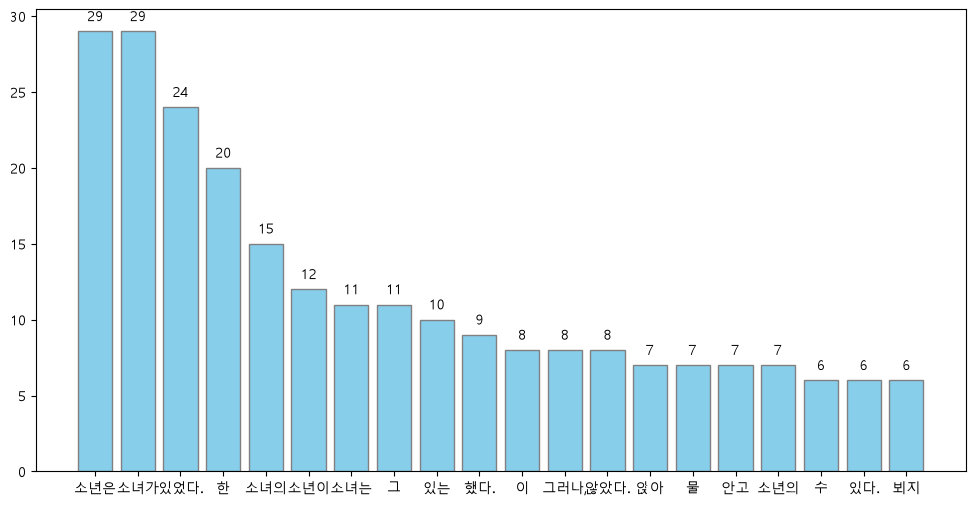

In [10]:
# 상위 20개 단어 추출
top_words = sorted_word_counts.take(20)

# PySpark RDD 결과를 시각화를 위해 Python 리스트로 변환
words = [w for w, c in top_words]
counts = [c for w, c in top_words]

# 시각화 (Bar Chart with Korean font & value labels)
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc

# 한글 폰트 설정 (예: 맑은 고딕, 시스템에 따라 다를 수 있음)
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows
# plt.rcParams['font.family'] = 'NanumGothic'   # macOS/Linux 한글 폰트 예시
plt.rcParams['axes.unicode_minus'] = False      # 음수 부호 깨짐 방지

# Figure 설정
plt.figure(figsize=(12, 6))
bars = plt.bar(words, counts, color='skyblue', edgecolor='gray')

# 막대 위에 빈도 값 표시
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.5,
             f'{int(height)}', ha='center', va='bottom', fontsize=10)
